<center>МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ </center>
<center>ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ ВЫСШЕГО ОБРАЗОВАНИЯ </center>
<center>«НОВОСИБИРСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНИЧЕСКИЙ УНИВЕРСИТЕТ»</center>
<center>Кафедра Вычислительной техники </center>
<br>
<center> <b> <font size="5">  ОТЧЁТ </font>  </b>  </center>   
<center><font size="3">по лабораторной работе №3</font></center>
<center><font size="3">по дисциплине: «Ассоциативный анализ данных» </font></center>
<br>

Выполнили:
- Клименко К.В.
- Бадагов А.В.

Преподаватель: Альсова О.К.

<center>  Новосибирск, 2026  </center>

# Цель работ

Изучить возможности модуля «Ассоциативный анализ» python на примере решения прикладной задачи.

# Ход работы

In [ ]:
# Python 3.13.15
import pandas as pd
import numpy  as np
import math

%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import cm
import seaborn as sns

from itertools import combinations
import networkx as nx
from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.simplefilter('ignore', DeprecationWarning)

In [ ]:
df = pd.read_csv("./lab3_1.csv",
        sep=',',
        decimal='.',
        header=0
    )
display(df)

,Unnamed: 0,Музыкальный центр,Наушники,Провод HDMI,Домашний кинотеатр,Ноутбук,DVD-плеер,ЖК-телевизор,ПК,Холодильник,Принтер,Кредит
0,1,0,1,1,1,1,0,0,0,1,1,1
1,2,0,1,1,0,0,1,1,1,1,1,1
2,3,0,1,0,1,1,1,1,1,0,1,1
3,4,0,1,1,1,0,1,1,1,1,1,1
4,5,0,1,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1225,1226,1,1,0,0,0,0,0,0,0,0,0
1226,1227,1,1,0,0,0,0,0,0,0,0,0
1227,1228,1,1,0,0,0,0,0,0,0,0,0
1228,1229,1,1,0,0,0,0,0,0,0,0,0


In [ ]:
data=df.drop(columns=['Unnamed: 0'])
freq=data.mean().sort_values(ascending=False)
freq

,0
Кредит,0.495935
Провод HDMI,0.398374
Музыкальный центр,0.382114
Наушники,0.349593
ЖК-телевизор,0.308943
ПК,0.308943
Принтер,0.308943
Холодильник,0.284553
DVD-плеер,0.276423
Домашний кинотеатр,0.162602


,Количество,Доля
Провод HDMI,490,0.398374
Музыкальный центр,470,0.382114
Наушники,430,0.349593
Принтер,380,0.308943
ПК,380,0.308943
ЖК-телевизор,380,0.308943
Холодильник,350,0.284553
DVD-плеер,340,0.276423
Ноутбук,200,0.162602
Домашний кинотеатр,200,0.162602


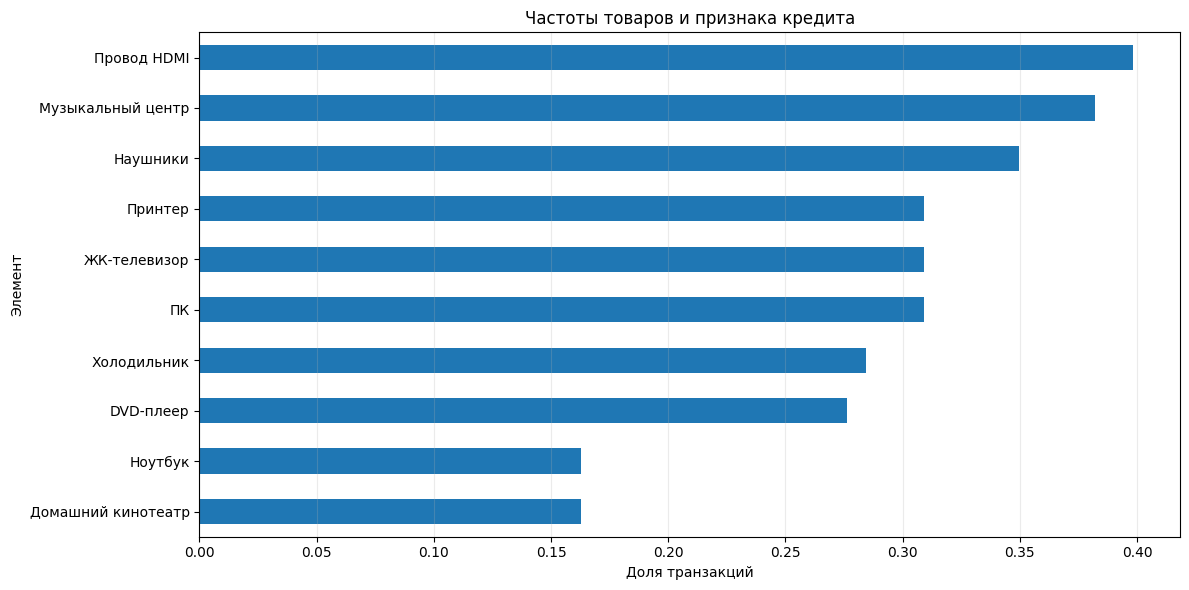

In [ ]:
product_columns = [col for col in data.columns if col != "Кредит"]
transactions = df[product_columns].astype(bool)
item_frequency = transactions.mean().sort_values(ascending=False)

frequency_table = pd.DataFrame({
    "Количество": transactions.sum().astype(int),
    "Доля": item_frequency
}).loc[item_frequency.index]

display(frequency_table)

plt.figure(figsize=(12, 6))
item_frequency.sort_values().plot(kind="barh")
plt.xlabel("Доля транзакций")
plt.ylabel("Элемент")
plt.title("Частоты товаров и признака кредита")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
products=[c for c in data.columns if c!='Кредит']
N=len(data)
credit=data['Кредит'].astype(bool).values
supp_credit=credit.mean()

rules_credit=[]
for r in range(1,len(products)+1):
    for comb in combinations(products,r):
        body_mask=np.ones(N,dtype=bool)
        for c in comb:
            body_mask &= data[c].astype(bool).values
        body_count=body_mask.sum()
        if body_count==0:
            continue
        joint=(body_mask & credit).sum()
        support=joint/N
        conf=joint/body_count
        if support>=0.1-1e-12 and conf>=0.5-1e-12:
            supp_body=body_count/N
            corr=support/math.sqrt(supp_body*supp_credit)
            lift=conf/supp_credit
            rules_credit.append((comb,support,conf,corr,lift,body_count,joint))
len(rules_credit)

18

In [ ]:
rules_sorted=sorted(rules_credit,key=lambda x:(-x[1],-x[2],-x[3],x[0]))
rules_sorted[:30]

[(('Холодильник',),
  np.float64(0.2601626016260163),
  np.float64(0.9142857142857143),
  np.float64(0.6925498485596882),
  np.float64(1.843559718969555),
  np.int64(350),
  np.int64(320)),
 (('ЖК-телевизор',),
  np.float64(0.25203252032520324),
  np.float64(0.8157894736842105),
  np.float64(0.6438800632157591),
  np.float64(1.6449525452976705),
  np.int64(380),
  np.int64(310)),
 (('DVD-плеер', 'ЖК-телевизор'),
  np.float64(0.23577235772357724),
  np.float64(0.90625),
  np.float64(0.6563841588082594),
  np.float64(1.8273565573770492),
  np.int64(320),
  np.int64(290)),
 (('DVD-плеер',),
  np.float64(0.23577235772357724),
  np.float64(0.8529411764705882),
  np.float64(0.6367861688820353),
  np.float64(1.7198649951783993),
  np.int64(340),
  np.int64(290)),
 (('Музыкальный центр',),
  np.float64(0.21138211382113822),
  np.float64(0.5531914893617021),
  np.float64(0.4855785584735493),
  np.float64(1.11545169166376),
  np.int64(470),
  np.int64(260)),
 (('Наушники',),
  np.float64(0.17886

In [ ]:
# build dataframe of rules
rows=[]
for i,(comb,support,conf,corr,lift,body_count,joint) in enumerate(rules_sorted,1):
    rows.append({
        "№":i,
        "LHS":" + ".join(comb),
        "RHS":"С кредитом",
        "support":float(support),
        "confidence":float(conf),
        "correlation":float(corr),
        "lift":float(lift),
        "body_count":int(body_count),
        "joint_count":int(joint)
    })
rules_df=pd.DataFrame(rows)
rules_df.round(4)

,№,LHS,RHS,support,confidence,correlation,lift,body_count,joint_count
0,1,Холодильник,С кредитом,0.2602,0.9143,0.6925,1.8436,350,320
1,2,ЖК-телевизор,С кредитом,0.2520,0.8158,0.6439,1.6450,380,310
2,3,DVD-плеер + ЖК-телевизор,С кредитом,0.2358,0.9062,0.6564,1.8274,320,290
3,4,DVD-плеер,С кредитом,0.2358,0.8529,0.6368,1.7199,340,290
4,5,Музыкальный центр,С кредитом,0.2114,0.5532,0.4856,1.1155,470,260
5,6,Наушники,С кредитом,0.1789,0.5116,0.4296,1.0316,430,220
6,7,Наушники + Домашний кинотеатр,С кредитом,0.1545,1.0000,0.5581,2.0164,190,190
7,8,Домашний кинотеатр,С кредитом,0.1545,0.9500,0.5440,1.9156,200,190
8,9,Провод HDMI + ЖК-телевизор,С кредитом,0.1545,0.7917,0.4966,1.5963,240,190
9,10,Провод HDMI + DVD-плеер + ЖК-телевизор,С кредитом,0.1463,0.9000,0.5153,1.8148,200,180


In [ ]:
# Вывод первых 10 правил с наибольшей поддержкой

top10 = rules_df.head(10).copy()

display(
    top10.style.format({
        "support": "{:.4f}",
        "confidence": "{:.4f}",
        "correlation": "{:.4f}",
        "lift": "{:.4f}"
    })
)

,№,LHS,RHS,support,confidence,correlation,lift,body_count,joint_count
0,1,Холодильник,С кредитом,0.2602,0.9143,0.6925,1.8436,350,320
1,2,ЖК-телевизор,С кредитом,0.2520,0.8158,0.6439,1.6450,380,310
2,3,DVD-плеер + ЖК-телевизор,С кредитом,0.2358,0.9062,0.6564,1.8274,320,290
3,4,DVD-плеер,С кредитом,0.2358,0.8529,0.6368,1.7199,340,290
4,5,Музыкальный центр,С кредитом,0.2114,0.5532,0.4856,1.1155,470,260
5,6,Наушники,С кредитом,0.1789,0.5116,0.4296,1.0316,430,220
6,7,Наушники + Домашний кинотеатр,С кредитом,0.1545,1.0000,0.5581,2.0164,190,190
7,8,Домашний кинотеатр,С кредитом,0.1545,0.9500,0.5440,1.9156,200,190
8,9,Провод HDMI + ЖК-телевизор,С кредитом,0.1545,0.7917,0.4966,1.5963,240,190
9,10,Провод HDMI + DVD-плеер + ЖК-телевизор,С кредитом,0.1463,0.9000,0.5153,1.8148,200,180


,Правило,LHS,support,confidence,correlation
0,R1,Холодильник,0.2602,0.9143,0.6925
1,R2,ЖК-телевизор,0.2520,0.8158,0.6439
2,R3,DVD-плеер + ЖК-телевизор,0.2358,0.9062,0.6564
3,R4,DVD-плеер,0.2358,0.8529,0.6368
4,R5,Музыкальный центр,0.2114,0.5532,0.4856
5,R6,Наушники,0.1789,0.5116,0.4296
6,R7,Наушники + Домашний кинотеатр,0.1545,1.0000,0.5581
7,R8,Домашний кинотеатр,0.1545,0.9500,0.5440
8,R9,Провод HDMI + ЖК-телевизор,0.1545,0.7917,0.4966
9,R10,Провод HDMI + DVD-плеер + ЖК-телевизор,0.1463,0.9000,0.5153


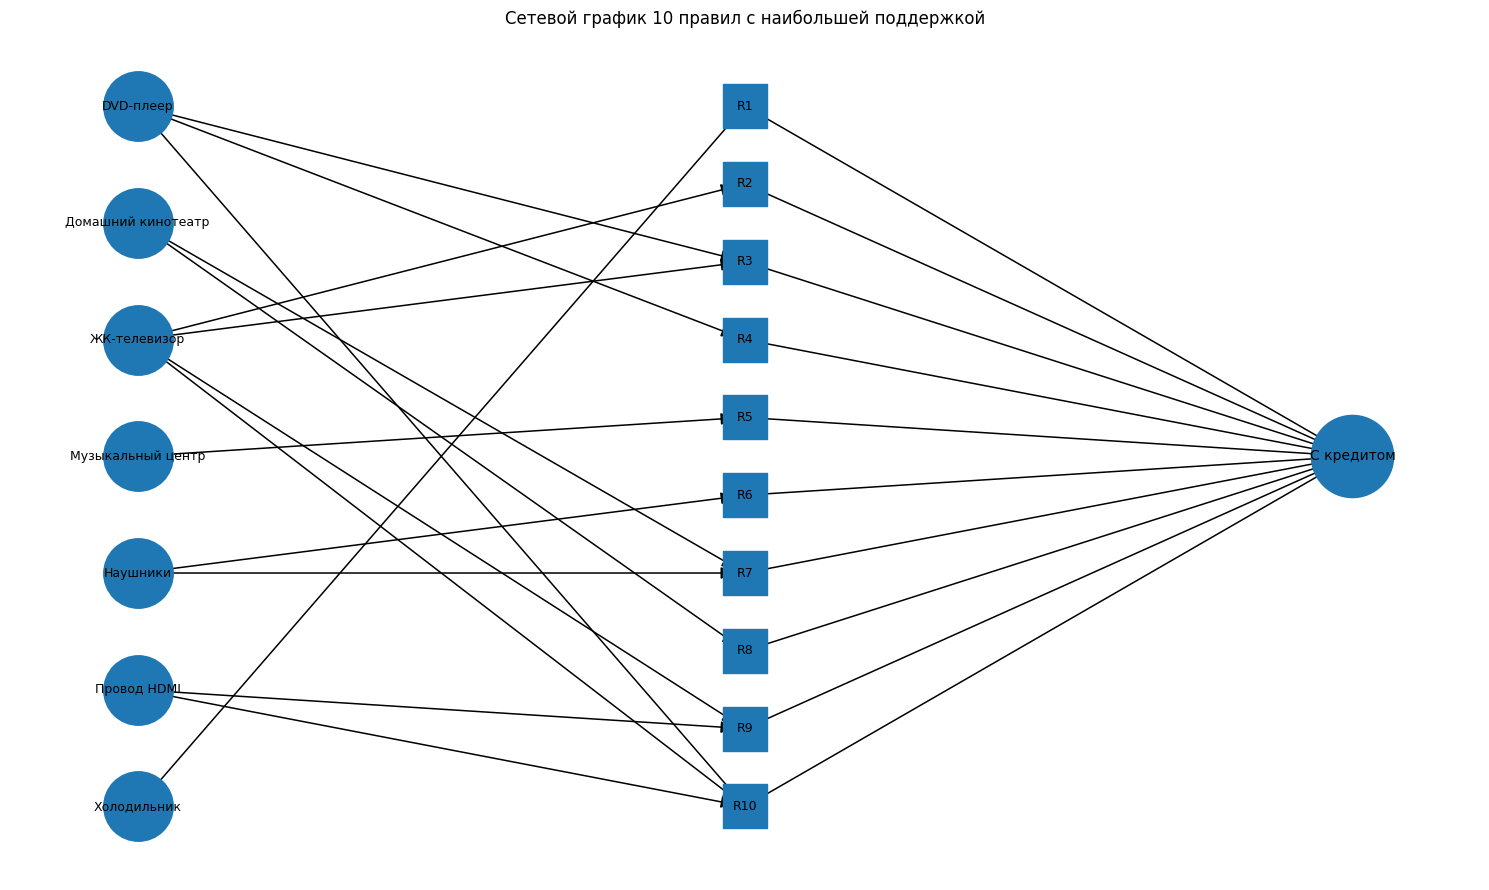

In [ ]:
# Подготовка 10 правил с максимальной поддержкой
top10_graph = rules_df.head(10).copy()

top10_graph = top10_graph.reset_index().rename(columns={"№": "rule_num"})
top10_graph["Правило"] = [
    f"R{i+1}"
    for i in range(len(top10_graph))
]

mapping_table = top10_graph[
    ["Правило", "LHS", "support", "confidence", "correlation"]
].copy()

display(
    mapping_table.style.format({
        "support": "{:.4f}",
        "confidence": "{:.4f}",
        "correlation": "{:.4f}"
    })
)

G = nx.DiGraph()

target = "С кредитом"
G.add_node(target, kind="target")

all_items = set()

for _, row in top10_graph.iterrows():
    rule_node = row["Правило"]
    G.add_node(rule_node, kind="rule")

    lhs_items = [x.strip() for x in row["LHS"].split(" + ")]

    for item in lhs_items:
        all_items.add(item)
        G.add_node(item, kind="item")
        G.add_edge(item, rule_node)

    G.add_edge(rule_node, target)

# Ручное расположение по трем уровням:
# товары -> правила -> "С кредитом"
pos = {}

item_nodes = sorted(all_items)
for i, item in enumerate(item_nodes):
    y = 0 if len(item_nodes) == 1 else 1 - 2 * i / (len(item_nodes) - 1)
    pos[item] = (0, y)

rule_nodes = top10_graph["Правило"].tolist()
for i, rule_node in enumerate(rule_nodes):
    y = 0 if len(rule_nodes) == 1 else 1 - 2 * i / (len(rule_nodes) - 1)
    pos[rule_node] = (1, y)

pos[target] = (2, 0)

plt.figure(figsize=(15, 9))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_size=2500
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=rule_nodes,
    node_size=1000,
    node_shape="s"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=[target],
    node_size=3500
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=18,
    width=1.1
)

nx.draw_networkx_labels(
    G, pos,
    labels={node: node for node in item_nodes},
    font_size=9
)

nx.draw_networkx_labels(
    G, pos,
    labels={node: node for node in rule_nodes},
    font_size=9
)

nx.draw_networkx_labels(
    G, pos,
    labels={target: target},
    font_size=10
)

plt.title("Сетевой график 10 правил с наибольшей поддержкой")
plt.axis("off")
plt.tight_layout()

plt.savefig("association_network_top10.png", dpi=180, bbox_inches="tight")
plt.show()

#Вывод

В ходе лабораторной работы был проведён ассоциативный анализ данных о покупках бытовой и электронной техники и использовании кредита. Исходный набор содержал 1230 записей о покупателях. Для поиска закономерностей были использованы минимальная поддержка 0,1 и минимальная достоверность 0,5.
В результате анализа было выявлено 18 ассоциативных правил, в которых следствием является использование кредита. Для каждого правила были рассчитаны показатели поддержки, достоверности и корреляции.
Наибольшую поддержку имеет правило «Холодильник → С кредитом»: support = 0,2602, confidence = 0,9143, correlation = 0,6925. Это означает, что 26,02 % всех покупателей одновременно приобрели холодильник и использовали кредит, при этом среди покупателей холодильника кредит использовали 91,43 %.
Также сильная зависимость наблюдается для правила «ЖК-телевизор → С кредитом», для которого support = 0,2520, confidence = 0,8158 и correlation = 0,6439. Для совместной покупки DVD-плеера и ЖК-телевизора получено правило с support = 0,2358 и confidence = 0,9062, то есть в 90,62 % случаев такой совместной покупки использовался кредит.
Высокую достоверность имеет правило «Домашний кинотеатр → С кредитом»: confidence = 0,95. Кроме того, для некоторых комбинаций товаров были получены правила с confidence = 1,0. Например, при одновременной покупке наушников и домашнего кинотеатра во всех соответствующих наблюдениях использовался кредит. Однако поддержка таких правил ниже, поэтому они встречаются реже в общей совокупности покупателей.
Наименее выраженная связь среди найденных одиночных правил наблюдается для музыкального центра и наушников: confidence составляет соответственно 0,5532 и 0,5116. Эти значения лишь немного превышают установленный порог 0,5.
Построенный сетевой график позволил наглядно представить взаимосвязи между товарами и использованием кредита. На основании полученных результатов можно сделать вывод, что наиболее выраженная связь с использованием кредита наблюдается при приобретении холодильников, ЖК-телевизоров, DVD-плееров и домашних кинотеатров, а также некоторых комбинаций этих товаров.
Таким образом, в ходе лабораторной работы были освоены методы ассоциативного анализа данных, рассчитаны основные характеристики ассоциативных правил и выявлены закономерности между приобретаемой техникой и использованием кредита. Следует учитывать, что обнаруженные правила характеризуют статистическую взаимосвязь признаков в исследуемом наборе данных и не свидетельствуют о причинно-следственной зависимости.